# Tokyo 2020 Olympics – Data Analysis

Analysis of the Tokyo 2020 Olympic Games (held in 2021): data cleaning and merging of six datasets, the relation between a country's GDP and its medals, regression and classification of national success, a hypothesis test on gender balance, a time-series analysis of 120 years of Olympic history, a small retrieval-augmented question-answering assistant (Gemini) and a quiz built from web-scraped facts.

**Data** (see the README for download links): `Athletes.xlsx`, `Coaches.xlsx`, `EntriesGender.xlsx`, `Medals.xlsx`, `Teams.xlsx` (Tokyo 2020), `gdp.csv` (World Bank GDP by country and year) and `athlete_events.csv` (Olympic history 1896–2016). Put the files into a `data/` folder next to this notebook, or into Google Drive when running in Colab.

# Loading the data

In [1]:
import os

# Data folder: Google Drive in Colab, ./data locally
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/Colab Notebooks/1.semestar/Projekti/OI_2021/Datasets'
except ImportError:
    DATA_DIR = 'data'

def data_path(name):
    return os.path.join(DATA_DIR, name)

Mounted at /content/drive


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
medals = pd.read_excel(data_path('Medals.xlsx'))                 # country ranking by medals
teams = pd.read_excel(data_path('Teams.xlsx'))                   # teams by discipline and event
athletes = pd.read_excel(data_path('Athletes.xlsx'))             # athletes (name, country, discipline)
coaches = pd.read_excel(data_path('Coaches.xlsx'))               # coaches by discipline
entries_gender = pd.read_excel(data_path('EntriesGender.xlsx'))  # female, male and total entries per discipline
gdp_data = pd.read_csv(data_path('gdp.csv'))                     # GDP of the participating countries

/usr/local/lib/python3.11/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.11/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [8]:
medals.head()

,Rank,Team/NOC,Gold,Silver,Bronze,Total,Rank by Total
0,1,United States of America,39,41,33,113,1
1,2,People's Republic of China,38,32,18,88,2
2,3,Japan,27,14,17,58,5
3,4,Great Britain,22,21,22,65,4
4,5,ROC,20,28,23,71,3


In [ ]:
teams.head()

,Name,Discipline,NOC,Event
0,Belgium,3x3 Basketball,Belgium,Men
1,China,3x3 Basketball,People's Republic of China,Men
2,China,3x3 Basketball,People's Republic of China,Women
3,France,3x3 Basketball,France,Women
4,Italy,3x3 Basketball,Italy,Women


In [ ]:
athletes.head()

,Name,NOC,Discipline
0,AALERUD Katrine,Norway,Cycling Road
1,ABAD Nestor,Spain,Artistic Gymnastics
2,ABAGNALE Giovanni,Italy,Rowing
3,ABALDE Alberto,Spain,Basketball
4,ABALDE Tamara,Spain,Basketball


In [ ]:
coaches.head()

,Name,NOC,Discipline,Event
0,ABDELMAGID Wael,Egypt,Football,NaN
1,ABE Junya,Japan,Volleyball,NaN
2,ABE Katsuhiko,Japan,Basketball,NaN
3,ADAMA Cherif,Côte d'Ivoire,Football,NaN
4,AGEBA Yuya,Japan,Volleyball,NaN


In [ ]:
entries_gender.head()

,Discipline,Female,Male,Total
0,3x3 Basketball,32,32,64
1,Archery,64,64,128
2,Artistic Gymnastics,98,98,196
3,Artistic Swimming,105,0,105
4,Athletics,969,1072,2041


In [ ]:
gdp_data.head()

,Country Name,Code,1960,1961,1962,1963,1964,1965,1966,1967,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,Unnamed: 65
0,Aruba,ABW,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.534637e+09,2.727850e+09,2.790849e+09,2.962905e+09,2.983637e+09,3.092430e+09,3.202189e+09,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,1.931311e+10,1.972349e+10,2.149392e+10,2.573321e+10,2.352744e+10,2.681057e+10,2.915216e+10,3.017317e+10,...,9.505214e+11,9.642424e+11,9.848071e+11,9.199300e+11,8.733549e+11,9.853557e+11,1.012853e+12,1.009910e+12,9.207923e+11,NaN
2,Afghanistan,AFG,5.377778e+08,5.488889e+08,5.466667e+08,7.511112e+08,8.000000e+08,1.006667e+09,1.400000e+09,1.673333e+09,...,1.990732e+10,2.014640e+10,2.049713e+10,1.913421e+10,1.811656e+10,1.875347e+10,1.805323e+10,1.879945e+10,2.011614e+10,NaN
3,Africa Western and Central,AFW,1.040428e+10,1.112805e+10,1.194335e+10,1.267652e+10,1.383858e+10,1.486247e+10,1.583285e+10,1.442643e+10,...,7.275714e+11,8.207876e+11,8.649666e+11,7.607297e+11,6.905430e+11,6.837416e+11,7.416916e+11,7.945725e+11,7.845876e+11,NaN
4,Angola,AGO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.280529e+11,1.367099e+11,1.457122e+11,1.161936e+11,1.011239e+11,1.221238e+11,1.013532e+11,8.941719e+10,5.837598e+10,NaN


In [ ]:
datasets = {
    "Athletes": athletes,
    "Coaches": coaches,
    "Entries Gender": entries_gender,
    "GDP Data": gdp_data,
    "Medals": medals,
    "Teams": teams
}

print("Missing values in all datasets:\n")

for name, dataset in datasets.items():
    print(f"Missing values in dataset '{name}':")
    print(dataset.isnull().sum())
    print("-" * 50)

Missing values in all datasets:

Missing values in dataset 'Athletes':
Name          0
NOC           0
Discipline    0
dtype: int64
--------------------------------------------------
Missing values in dataset 'Coaches':
Name            0
NOC             0
Discipline      0
Event         145
dtype: int64
--------------------------------------------------
Missing values in dataset 'Entries Gender':
Discipline    0
Female        0
Male          0
Total         0
dtype: int64
--------------------------------------------------
Missing values in dataset 'GDP Data':
Country Name      0
Code              0
1960            138
1961            132
1962            129
               ... 
2017             10
2018             10
2019             13
2020             24
Unnamed: 65     266
Length: 64, dtype: int64
--------------------------------------------------
Missing values in dataset 'Medals':
Rank             0
Team/NOC         0
Gold             0
Silver           0
Bronze           0
Total  

**All files were loaded. Observations:**

**Athletes.xlsx:** athletes (name, NOC – National Olympic Committee, discipline). No missing values.

**Coaches.xlsx:** name, NOC, discipline and event. The "Event" column has many missing values.

**EntriesGender.xlsx:** number of female, male and total entries per discipline. No missing values.

**gdp.csv:** GDP of countries over many years, with many gaps in the time series.

**Medals.xlsx:** team ranking by medals. No missing values.

**Teams.xlsx:** teams by discipline and event.

# Data cleaning

**Cleaning plan:**

- Remove the empty column "Unnamed: 65" from the GDP dataset.
- Fill the missing values in the "Event" column of the Coaches dataset.
- Check for duplicate or invalid rows in all datasets.

In [9]:
# Missing GDP values

# Convert the year columns (all except the first two) to numbers
for col in gdp_data.columns[2:]:
    gdp_data[col] = pd.to_numeric(gdp_data[col], errors='coerce')

# Linear interpolation along the years (1960 onwards)
gdp_data.iloc[:, 2:] = gdp_data.iloc[:, 2:].interpolate(method='linear', axis=1)

# Fill the remaining gaps with the column mean
gdp_data.iloc[:, 2:] = gdp_data.iloc[:, 2:].fillna(gdp_data.mean(numeric_only=True))

gdp_data.isnull().sum()

,0
Country Name,0
Code,0
1960,0
1961,0
1962,0
...,...
2017,0
2018,0
2019,0
2020,0


In [10]:
# Drop the empty column from the GDP data
gdp_data = gdp_data.drop(columns=["Unnamed: 65"], errors="ignore")

# Fill missing events with "Unknown"
coaches["Event"] = coaches["Event"].fillna("Unknown")

# Remove duplicate rows
athletes = athletes.drop_duplicates()
coaches = coaches.drop_duplicates()

print("Dataset shapes after cleaning:")
print(f"Athletes: {athletes.shape}")
print(f"Coaches: {coaches.shape}")
print(f"Entries Gender: {entries_gender.shape}")
print(f"GDP: {gdp_data.shape}")
print(f"Medals: {medals.shape}")
print(f"Teams: {teams.shape}")

Dataset shapes after cleaning:
Athletes: (11084, 3)
Coaches: (393, 4)
Entries Gender: (46, 4)
GDP: (266, 63)
Medals: (93, 7)
Teams: (743, 4)


# Data analysis

**Questions:**

1. How does GDP relate to the number of medals? Correlation and a scatter plot.
2. How are the medals distributed across countries? Bar plot of the top 10.
3. Athletes and teams: number of athletes per team and per discipline.

**Merging the datasets**

- **Athletes and Teams** on `NOC`: most NOC values from Athletes exist in Teams (10,146 of 11,084), and all 743 NOC codes from Teams exist in Athletes. The merge has 215,971 rows and 6 columns (one row per athlete–team pair of the same country).
- **Medals and GDP** on the country name (`Team/NOC` in Medals, `Country Name` in GDP): 78 countries match, giving 78 rows and 70 columns.

Countries whose names differ between the two sources (e.g. "United States of America" vs "United States", "People's Republic of China" vs "China") do not match and are not part of the GDP analysis; see *Limitations* at the end.

In [ ]:
# Merge Athletes and Teams on NOC
athletes_teams_merged = pd.merge(
    athletes, teams, on="NOC", how="inner", suffixes=("_Athletes", "_Teams")
)
print("Shape of the Athletes-Teams merge:", athletes_teams_merged.shape)
print(athletes_teams_merged.head())

# Remove surrounding spaces in country names
gdp_data["Country Name"] = gdp_data["Country Name"].str.strip()
medals["Team/NOC"] = medals["Team/NOC"].str.strip()

# Merge Medals and GDP on the country name
medals_gdp_merged = pd.merge(
    medals,
    gdp_data,
    left_on="Team/NOC",
    right_on="Country Name",
    how="inner"
)
print("Shape of the Medals-GDP merge:", medals_gdp_merged.shape)
print(medals_gdp_merged.head())

Shape of the Athletes-Teams merge: (215971, 6)
     Name_Athletes     NOC  Discipline_Athletes       Name_Teams  \
0  AALERUD Katrine  Norway         Cycling Road  Mol A./Sorum C.   
1  AALERUD Katrine  Norway         Cycling Road           Norway   
2  AALERUD Katrine  Norway         Cycling Road           Norway   
3      ABAD Nestor   Spain  Artistic Gymnastics            Spain   
4      ABAD Nestor   Spain  Artistic Gymnastics            Spain   

      Discipline_Teams       Event  
0     Beach Volleyball         Men  
1             Handball         Men  
2             Handball       Women  
3              Archery  Mixed Team  
4  Artistic Gymnastics  Men's Team  
Shape of the Medals-GDP merge: (78, 70)
   Rank     Team/NOC  Gold  Silver  Bronze  Total  Rank by Total Country Name  \
0     3        Japan    27      14      17     58              5        Japan   
1     6    Australia    17       7      22     46              6    Australia   
2     7  Netherlands    10      12     

## 1. How does GDP relate to the number of medals?

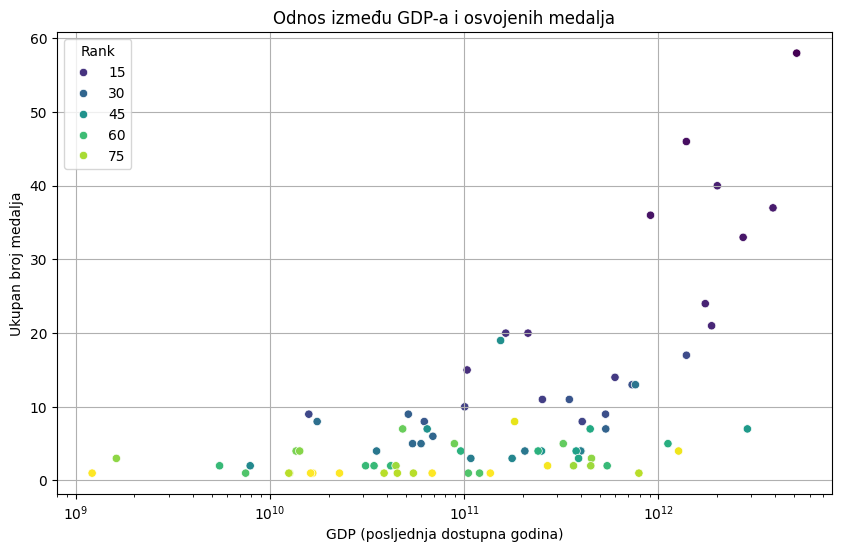

Correlation between GDP and total medals:
            GDP     Total
GDP    1.000000  0.767247
Total  0.767247  1.000000


In [ ]:
# Correlation between GDP and total medals
gdp_columns = gdp_data.columns[2:-1]  # year columns
latest_gdp_year = gdp_columns[-1]     # most recent year with GDP data

medals_gdp_merged["GDP"] = medals_gdp_merged[latest_gdp_year]
correlation = medals_gdp_merged[["GDP", "Total"]].corr()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=medals_gdp_merged, x="GDP", y="Total", hue="Rank", palette="viridis")
plt.title("GDP vs. total medals")
plt.xlabel("GDP (latest available year, USD)")
plt.ylabel("Total medals")
plt.xscale("log")  # log scale because GDP differs by orders of magnitude
plt.grid(True)
plt.show()

print("Correlation between GDP and total medals:")
print(correlation)

**Result:** the correlation coefficient between GDP and total medals is **0.767**, a strong positive relation: countries with a higher GDP tend to win more medals. GDP is shown on a log scale because it differs by orders of magnitude between countries.

## 2. Medal distribution by country

<ipython-input-18-90f3b4a6b161>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


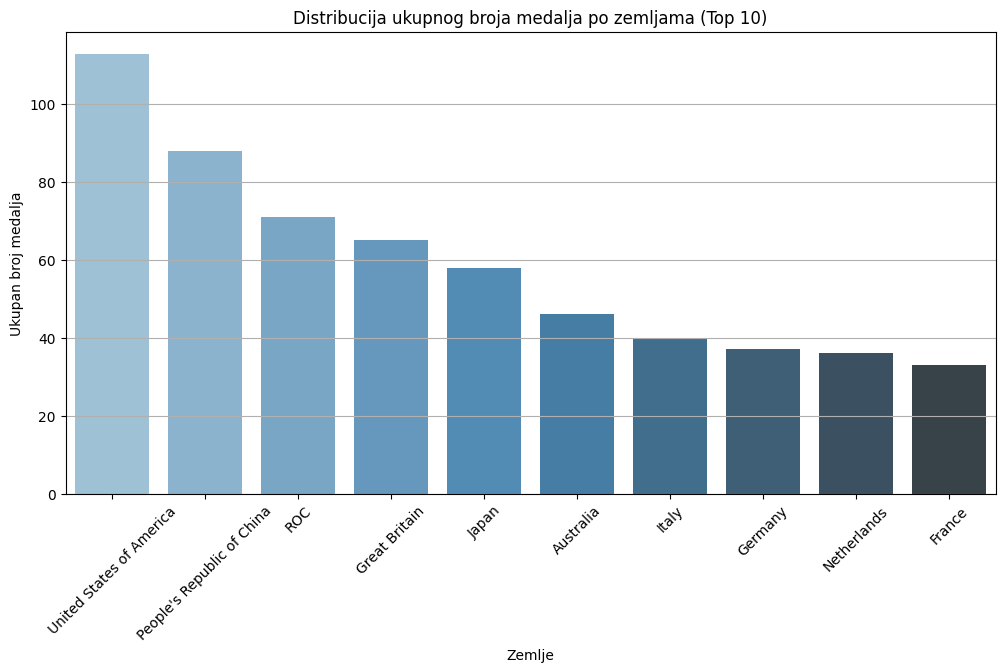

Top 10 countries by total medals:
Team/NOC
United States of America      113
People's Republic of China     88
ROC                            71
Great Britain                  65
Japan                          58
Australia                      46
Italy                          40
Germany                        37
Netherlands                    36
France                         33
Name: Total, dtype: int64


In [ ]:
medals_distribution = medals.groupby("Team/NOC")["Total"].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=medals_distribution.index[:10],  # top 10 countries
    y=medals_distribution.values[:10],
    palette="Blues_d"
)
plt.title("Total medals by country (top 10)")
plt.xlabel("Country")
plt.ylabel("Total medals")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

print("Top 10 countries by total medals:")
print(medals_distribution.head(10))

## 3. Athletes and teams

- Number of athletes per team (bar plot, top 10)
- Distribution of athletes across disciplines (pie chart, top 10)

<ipython-input-19-20f4aad59de9>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


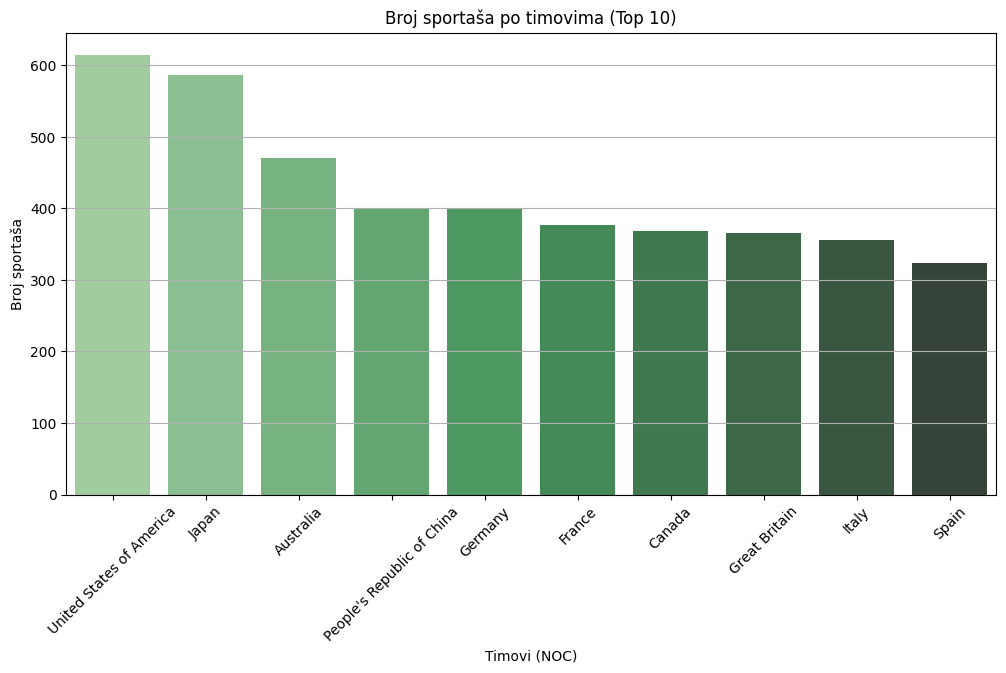

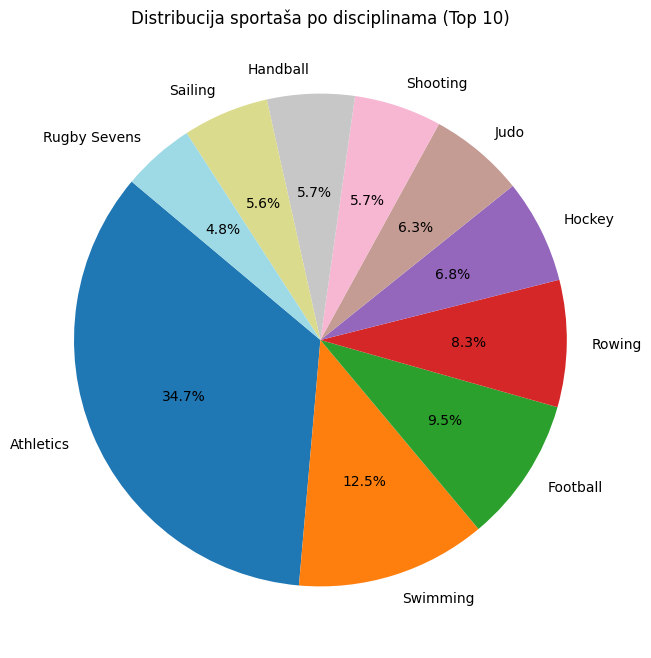

Top 10 teams by number of athletes:
NOC
United States of America      615
Japan                         586
Australia                     470
People's Republic of China    401
Germany                       400
France                        377
Canada                        368
Great Britain                 366
Italy                         356
Spain                         324
Name: Name, dtype: int64

Top 10 disciplines by number of athletes:
Discipline
Athletics       2068
Swimming         743
Football         567
Rowing           496
Hockey           406
Judo             373
Shooting         342
Handball         342
Sailing          336
Rugby Sevens     283
Name: Name, dtype: int64


In [ ]:
# Number of athletes per team (NOC)
athletes_per_team = athletes.groupby("NOC")["Name"].count().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=athletes_per_team.index[:10],
    y=athletes_per_team.values[:10],
    palette="Greens_d"
)
plt.title("Number of athletes per team (top 10)")
plt.xlabel("Team (NOC)")
plt.ylabel("Number of athletes")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

# Athletes per discipline
athletes_per_discipline = athletes.groupby("Discipline")["Name"].count().sort_values(ascending=False)

plt.figure(figsize=(8, 8))
athletes_per_discipline[:10].plot.pie(
    autopct='%1.1f%%', startangle=140, colormap="tab20", ylabel="",
    title="Athletes per discipline (top 10)"
)
plt.show()

print("Top 10 teams by number of athletes:")
print(athletes_per_team.head(10))

print("\nTop 10 disciplines by number of athletes:")
print(athletes_per_discipline.head(10))

# Regression

Predict the total number of medals from GDP and the number of athletes with multiple linear regression.

In [ ]:
# Number of athletes per country
medals_gdp_merged["Athletes"] = medals_gdp_merged["Team/NOC"].map(
    athletes.groupby("NOC")["Name"].count()
)

print("Added column 'Athletes':")
print(medals_gdp_merged[["Team/NOC", "Athletes"]].head())

Added column 'Athletes':
      Team/NOC  Athletes
0        Japan       586
1    Australia       470
2  Netherlands       274
3       France       377
4      Germany       400


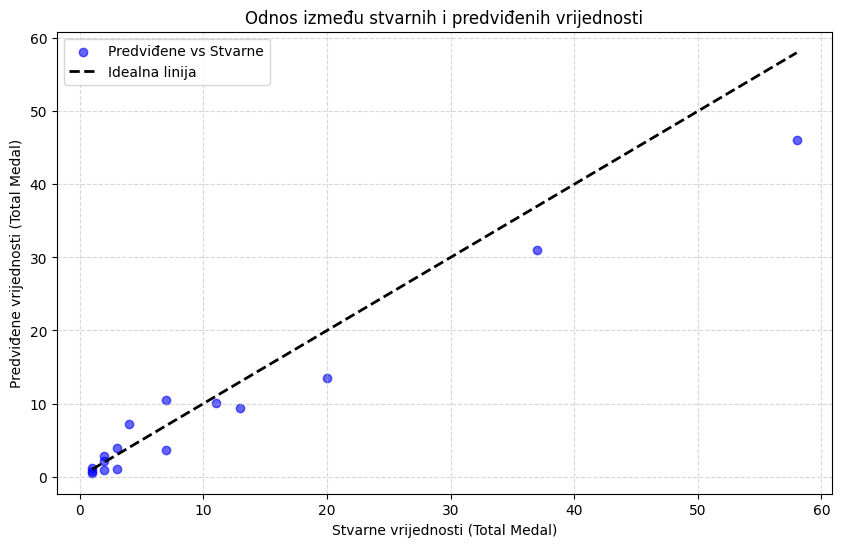

R^2: 0.9261515713879891
MSE: 17.17437517908079
Coefficients: [-1.07668567e-12  8.80223382e-02]
Intercept: 0.03941757239547172


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

regression_data = medals_gdp_merged[["GDP", "Athletes", "Total"]].dropna()

X = regression_data[["GDP", "Athletes"]]
y = regression_data["Total"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
coefficients = model.coef_
intercept = model.intercept_

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color="blue", alpha=0.6, label="Predicted vs actual")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2, label="Ideal line")
plt.title("Actual vs. predicted total medals")
plt.xlabel("Actual total medals")
plt.ylabel("Predicted total medals")
plt.legend()
plt.grid(alpha=0.5, linestyle="--")
plt.show()

print("R^2:", r2)
print("MSE:", mse)
print("Coefficients:", coefficients)
print("Intercept:", intercept)

**Results of the multiple linear regression:**

| | Value | Interpretation |
|---|---|---|
| GDP coefficient | ≈ -1.08e-12 | practically no effect once the number of athletes is known |
| Athletes coefficient | ≈ 0.088 | each additional athlete adds about 0.088 medals |
| Intercept | ≈ 0.039 | |
| R² (test set) | 0.926 | the model explains most of the variance |
| MSE (test set) | 17.17 | |

The number of athletes carries almost all of the predictive power. GDP is strongly correlated with the team size, so its own coefficient is close to zero. The test set has only 16 countries, so R² should be read with care.

# Classification

Countries are split into four success classes by the quartiles of their total medals (Low, Medium, High, Very High), and a logistic regression predicts the class from GDP and the number of athletes.

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


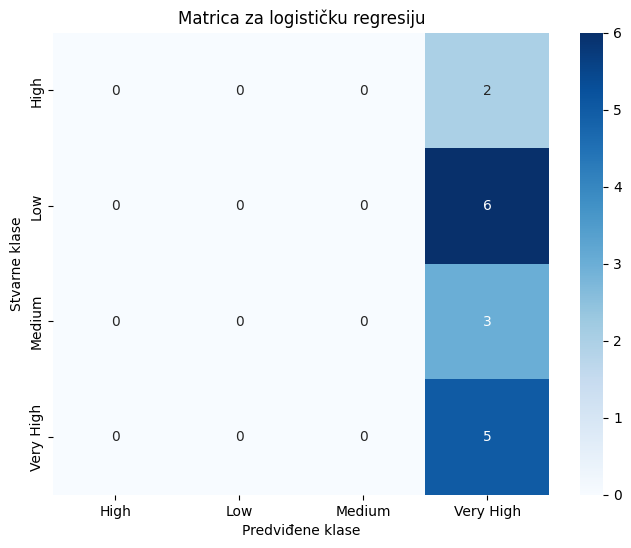

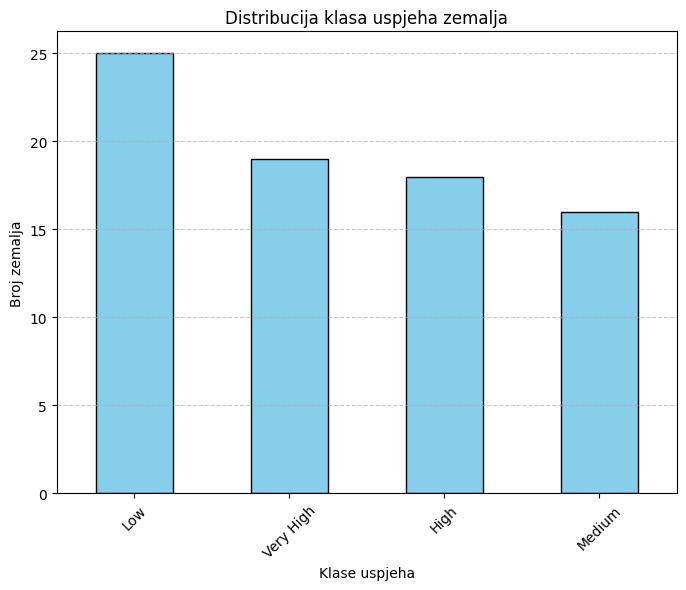

Classification report:
               precision    recall  f1-score   support

        High       0.00      0.00      0.00         2
         Low       0.00      0.00      0.00         6
      Medium       0.00      0.00      0.00         3
   Very High       0.31      1.00      0.48         5

    accuracy                           0.31        16
   macro avg       0.08      0.25      0.12        16
weighted avg       0.10      0.31      0.15        16



In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

# Success classes from the total number of medals (quartiles)
medals_gdp_merged["Success_Class"] = pd.qcut(
    medals_gdp_merged["Total"], q=4, labels=["Low", "Medium", "High", "Very High"]
)

# Encode the classes as numbers
label_encoder = LabelEncoder()
medals_gdp_merged["Success_Class_Label"] = label_encoder.fit_transform(medals_gdp_merged["Success_Class"])

# Features and target
X_classification = medals_gdp_merged[["GDP", "Athletes"]]
y_classification = medals_gdp_merged["Success_Class_Label"]

# Train/test split
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_classification, y_classification, test_size=0.2, random_state=42
)

# Logistic regression
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_cls, y_train_cls)

# Predictions on the test set
y_pred_cls = logistic_model.predict(X_test_cls)

# Evaluation
classification_rep = classification_report(y_test_cls, y_pred_cls, target_names=label_encoder.classes_)
confusion_mat = confusion_matrix(y_test_cls, y_pred_cls)

# Confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_mat, annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion matrix – logistic regression")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.show()

# Class distribution
class_distribution = medals_gdp_merged["Success_Class"].value_counts()
class_distribution.plot(kind='bar', figsize=(8, 6), color="skyblue", edgecolor="black")
plt.title("Distribution of country success classes")
plt.xlabel("Success class")
plt.ylabel("Number of countries")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

# Results
print("Classification report:\n", classification_rep)

**Results:** the model has limited precision, especially for the Low, Medium and High classes. "Very High" reaches 31 % precision with 100 % recall: every country in this class is recognised, but many other countries are also predicted as "Very High". The confusion matrix shows that most predictions fall into this class. With unscaled features (GDP is in the order of 10¹²) and only 78 countries, logistic regression struggles; scaling the features (`StandardScaler`) and class weighting would be the next steps.

# Hypothesis testing

**Is there a statistically significant difference between the number of male and female athletes per discipline?**

- **Null hypothesis (H0):** there is no significant difference between the number of male and female athletes per discipline.
- **Alternative hypothesis (H1):** there is a significant difference.

A **t-test** compares the means of two groups:

- the *independent samples* t-test compares two separate groups,
- the *paired samples* t-test compares two measurements of the same units (here: men and women in the same discipline),
- the *one-sample* t-test compares one group with a fixed value.

Welch's independent t-test is used below; because every discipline has both a male and a female count, a paired test would be the stricter choice (see *Limitations*).

T-statistic: 0.29949672116231546
P-value: 0.7652624366726588
There is no statistically significant difference between the number of male and female competitors per discipline.


<Figure size 1200x600 with 0 Axes>

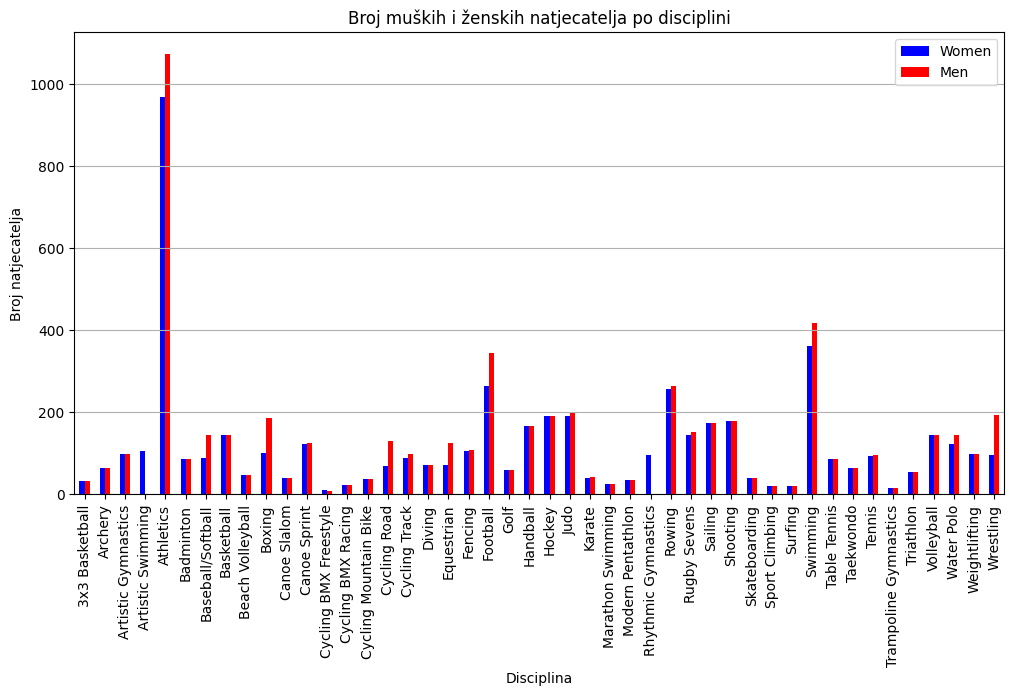

In [11]:
from scipy.stats import ttest_ind

# Total female and male competitors per discipline
gender_counts = entries_gender.groupby('Discipline')[['Female', 'Male']].sum()

t_stat, p_value = ttest_ind(gender_counts['Male'], gender_counts['Female'], equal_var=False)

print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")

alpha = 0.05
if p_value < alpha:
    print("There is a statistically significant difference between the number of male and female competitors per discipline.")
else:
    print("There is no statistically significant difference between the number of male and female competitors per discipline.")

gender_counts.plot(kind='bar', figsize=(12, 6), color=['blue', 'red'])
plt.title('Male and female competitors per discipline')
plt.xlabel('Discipline')
plt.ylabel('Number of competitors')
plt.xticks(rotation=90)
plt.legend(['Women', 'Men'])
plt.grid(axis='y')
plt.show()

**Results:**

- **T-statistic: 0.2949**, close to zero: the average numbers of male and female competitors per discipline are very similar.
- **P-value: 0.7652**, far above α = 0.05, so the null hypothesis cannot be rejected.

**Conclusion:** at Tokyo 2020 men did not dominate in the number of competitors per discipline. The bar chart shows that individual disciplines differ, but across all disciplines the numbers are balanced, which reflects the IOC's gender-equality rules for these Games.

# Time-series analysis (1896–2016)

In [13]:
olympics = pd.read_csv(data_path("athlete_events.csv"))

In [14]:
olympics.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [15]:
def missing_values_analysis(df):
    na_columns_ = [col for col in df.columns if df[col].isnull().sum() > 0]
    n_miss = df[na_columns_].isnull().sum().sort_values(ascending=True)
    ratio_ = (df[na_columns_].isnull().sum() / df.shape[0] * 100).sort_values(ascending=True)
    missing_df = pd.concat([n_miss, np.round(ratio_, 2)], axis=1, keys=['Total Missing Values', 'Ratio'])
    missing_df = pd.DataFrame(missing_df)
    return missing_df

def check_df(df, head=5):
    print("--------------------- Shape --------------------")
    print(df.shape)
    print("-------------------- Types ---------------------")
    print(df.dtypes)
    print("----------------- NaN Analysis -----------------")
    print(missing_values_analysis(df))
    print("--------------------- Head ---------------------")
    print(df.head())

check_df(olympics)

--------------------- Shape --------------------
(271116, 15)
-------------------- Types ---------------------
ID          int64
Name       object
Sex        object
Age       float64
Height    float64
Weight    float64
Team       object
NOC        object
Games      object
Year        int64
Season     object
City       object
Sport      object
Event      object
Medal      object
dtype: object
----------------- NaN Analysis -----------------
        Total Missing Values  Ratio
Age                     9474   3.49
Height                 60171  22.19
Weight                 62875  23.19
Medal                 231333  85.33
--------------------- Head ---------------------
   ID                      Name Sex   Age  Height  Weight            Team  \
0   1                 A Dijiang   M  24.0   180.0    80.0           China   
1   2                  A Lamusi   M  23.0   170.0    60.0           China   
2   3       Gunnar Nielsen Aaby   M  24.0     NaN     NaN         Denmark   
3   4      Edgar Li

In [16]:
# Cleaning: remove duplicates and rows without age, height or weight
olympics.drop_duplicates(inplace=True)
olympics.dropna(subset=['Age', 'Height', 'Weight'], inplace=True)

# The Medal column is not needed here
if 'Medal' in olympics.columns:
    olympics.drop(columns=['Medal'], inplace=True)

check_df(olympics)
print("Rows after cleaning:", olympics.shape[0])
print("NaN values after cleaning:", olympics.isnull().sum().sum())

--------------------- Shape --------------------
(206152, 14)
-------------------- Types ---------------------
ID          int64
Name       object
Sex        object
Age       float64
Height    float64
Weight    float64
Team       object
NOC        object
Games      object
Year        int64
Season     object
City       object
Sport      object
Event      object
dtype: object
----------------- NaN Analysis -----------------
Empty DataFrame
Columns: [Total Missing Values, Ratio]
Index: []
--------------------- Head ---------------------
   ID                      Name Sex   Age  Height  Weight         Team  NOC  \
0   1                 A Dijiang   M  24.0   180.0    80.0        China  CHN   
1   2                  A Lamusi   M  23.0   170.0    60.0        China  CHN   
4   5  Christine Jacoba Aaftink   F  21.0   185.0    82.0  Netherlands  NED   
5   5  Christine Jacoba Aaftink   F  21.0   185.0    82.0  Netherlands  NED   
6   5  Christine Jacoba Aaftink   F  25.0   185.0    82.0  Nether

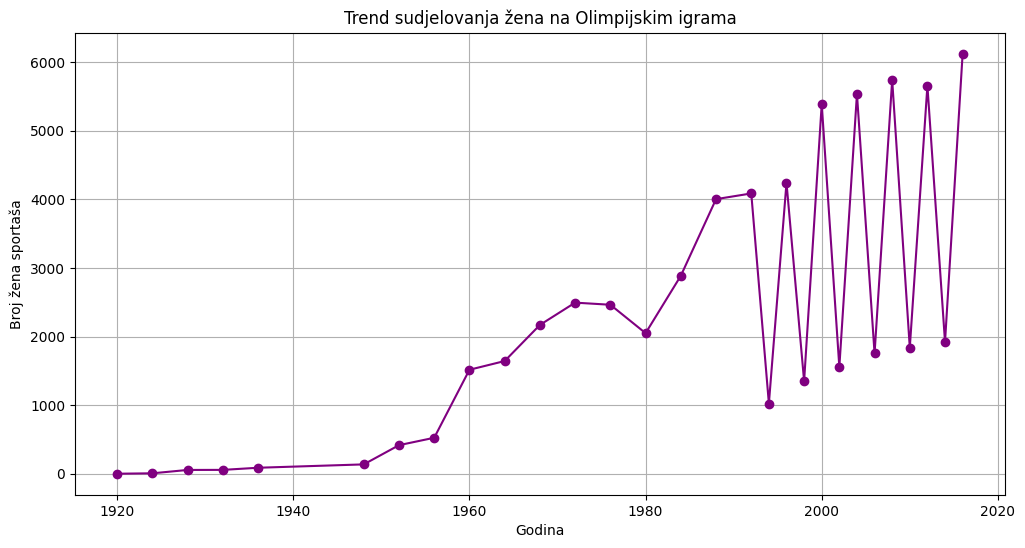

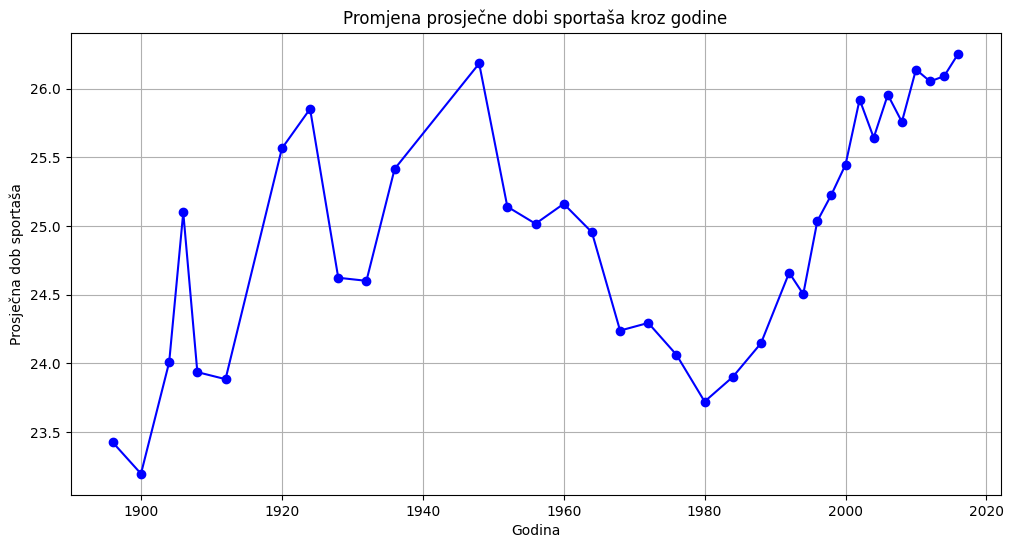

Year
1920     1
1924     7
1928    56
1932    57
1936    88
dtype: int64
Year
1896    23.425000
1900    23.197183
1904    24.008403
1906    25.099502
1908    23.936986
Name: Age, dtype: float64


In [17]:
# Number of female athletes per Games
women_participation = olympics[olympics['Sex'] == 'F'].groupby('Year').size()

plt.figure(figsize=(12, 6))
plt.plot(women_participation.index, women_participation.values, marker='o', linestyle='-', color='purple')
plt.xlabel('Year')
plt.ylabel('Number of female athletes')
plt.title('Participation of women in the Olympic Games')
plt.grid(True)
plt.show()

# Average athlete age per Games
average_age = olympics.groupby('Year')['Age'].mean()

plt.figure(figsize=(12, 6))
plt.plot(average_age.index, average_age.values, marker='o', linestyle='-', color='blue')
plt.xlabel('Year')
plt.ylabel('Average age')
plt.title('Average age of Olympic athletes over time')
plt.grid(True)
plt.show()

print(women_participation.head())
print(average_age.head())

**1. Participation of women**

- The number of female athletes grew strongly over time. It stayed low until the 1960s and then rose steeply, especially from the 1980s and 1990s, in line with global efforts for gender equality in sport.
- The zig-zag pattern comes from the alternating Summer and Winter Games (the Winter Games are much smaller).

**2. Average age**

- The average age was lowest between the 1950s and 1980s (just under 24 years) and has risen since then to over 26 years.
- Better training, sports medicine and rehabilitation allow longer careers.

Note: rows without height or weight were removed, which drops many early Games; the early years are therefore less representative.

# Question answering with an LLM (retrieval-augmented generation)

The assistant first **retrieves** facts from the project's own data: if the question mentions a Tokyo 2020 participant country, its row from `Medals.xlsx` (rank and gold/silver/bronze/total) is added to the prompt. The **generation** step then asks Gemini to answer, using the retrieved data when it is relevant. Without matching data the model answers from its own knowledge, which can contain mistakes.

Set the API key as the `GOOGLE_API_KEY` Colab secret or environment variable. **Never write the key into the notebook.**

In [ ]:
!pip install -q -U google-genai

In [ ]:
import os
from google import genai

GEMINI_MODEL = "gemini-3.6-flash"  # check https://ai.google.dev/models for current model names

try:
    from google.colab import userdata
    api_key = userdata.get('GOOGLE_API_KEY')
except ImportError:
    api_key = os.environ.get('GOOGLE_API_KEY')

client = genai.Client(api_key=api_key)

In [ ]:
def retrieve_medal_context(question):
    """Return the Tokyo 2020 medal rows of the countries mentioned in the question."""
    q = question.lower()
    rows = medals[medals["Team/NOC"].str.lower().apply(lambda country: country in q)]
    if rows.empty:
        return ""
    return rows[["Rank", "Team/NOC", "Gold", "Silver", "Bronze", "Total"]].to_string(index=False)


def answer_question(question):
    context = retrieve_medal_context(question)
    prompt = (
        "You are an expert on the Olympic Games. Answer the question precisely and briefly.\n"
        + (f"Use this Tokyo 2020 medal table data if it is relevant:\n{context}\n" if context else "")
        + f"Question: {question}"
    )
    try:
        response = client.models.generate_content(model=GEMINI_MODEL, contents=prompt)
        return response.text
    except Exception as e:
        return f"The answer could not be generated ({e})."


def question_session():
    print("Ask questions about the Olympic Games. Type 'exit' to stop.")
    while True:
        question = input("Question: ")
        if question.lower() == 'exit':
            print("Goodbye!")
            break
        print(f"\nAnswer: {answer_question(question)}\n")


question_session()

# Web scraping: an Olympic quiz

Facts about the Olympic Games are scraped with `requests` and BeautifulSoup from three Croatian- and Bosnian-language pages, filtered, and turned into true/false questions. A false variant is created by replacing "most" (*najviše*) with "least" (*najmanje*). The facts stay in their original language.

Sources: [hrsport.hr](https://hrsport.hr/zanimljivosti-o-olimpijskim-igrama-top-60/), [ahaslides.com](https://ahaslides.com/hr/blog/olympics-quiz/), [novostiplus.org](https://www.novostiplus.org/bs/zanimljivosti-o-olimpijskim-igrama-za-koje-sigurno-niste-culi-fascinantne-24-cinjenice-iz-istorije-oi/).

In [ ]:
import random
import requests
from bs4 import BeautifulSoup

# Croatian keywords used to keep relevant facts and drop navigation text
OLYMPIC_KEYWORDS = ["olimpijske", "igre", "medalje", "sport", "natjecanje", "plamen", "prstenovi", "rekordi", "atletika"]
NOISE_KEYWORDS = ["kolo", "kviz", "blog", "kategorije", "tutorial"]
QUESTION_KEYWORDS = ["održane", "osvojila", "prvi put", "godine", "medalje", "natjecanje", "rekordi"]


def scrape_olympics_facts(url):
    """Scrape facts about the Olympic Games from the given page."""
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        soup = BeautifulSoup(response.text, 'html.parser')

        facts = []
        if "ahaslides" in url:
            for li in soup.find_all('li'):
                text = li.text.strip()
                if len(text) > 15 and all(k not in text.lower() for k in NOISE_KEYWORDS):
                    facts.append(text)
        else:
            for li in soup.find_all('li'):
                fact = li.text.strip()
                if len(fact) > 15 and any(k in fact.lower() for k in OLYMPIC_KEYWORDS):
                    facts.append(fact)

        # Drop headings and other short or irrelevant items
        return [
            fact for fact in facts
            if len(fact.split()) > 3
            and not fact.lower().startswith("napredni")
            and not any(k in fact.lower() for k in NOISE_KEYWORDS)
        ]
    except Exception as e:
        print(f"Scraping failed for {url}: {e}")
        return []


def generate_questions(facts, used_questions):
    """Create true/false questions from the facts."""
    questions = []
    for fact in facts:
        if fact in used_questions:
            continue
        if any(k in fact.lower() for k in QUESTION_KEYWORDS):
            questions.append({"question": f"True or false? {fact}", "answer": "true"})
            used_questions.add(fact)

        if "najviše" in fact:  # "most" -> "least" makes a false statement
            fake_fact = fact.replace("najviše", "najmanje")
            if fake_fact not in used_questions:
                questions.append({"question": f"True or false? {fake_fact}", "answer": "false"})
                used_questions.add(fake_fact)
    return questions


def start_quiz(facts, rounds_of=10):
    print("Olympic Games quiz! Answer 'true', 'false' or 'exit'.")
    used_questions = set()

    while True:
        available = generate_questions(facts, used_questions)
        if not available:
            print("No more questions. Thanks for playing!")
            break

        score = 0
        questions = random.sample(available, min(rounds_of, len(available)))
        for i, q in enumerate(questions, start=1):
            print(f"Question {i}: {q['question']}")
            answer = input("Your answer (true/false): ").strip().lower()
            while answer not in ("true", "false", "exit"):
                answer = input("Please type 'true', 'false' or 'exit': ").strip().lower()
            if answer == "exit":
                print("Thanks for playing!")
                return
            if answer == q["answer"]:
                print("Correct!\n")
                score += 1
            else:
                print("Wrong!\n")
        print(f"Your score: {score}/{len(questions)}")


urls = [
    "https://hrsport.hr/zanimljivosti-o-olimpijskim-igrama-top-60/",
    "https://ahaslides.com/hr/blog/olympics-quiz/",
    "https://www.novostiplus.org/bs/zanimljivosti-o-olimpijskim-igrama-za-koje-sigurno-niste-culi-fascinantne-24-cinjenice-iz-istorije-oi/",
]

all_facts = [fact for url in urls for fact in scrape_olympics_facts(url)]
if all_facts:
    start_quiz(all_facts)
else:
    print("Could not fetch any facts for the quiz.")

# Limitations

- **Country names.** Medals and GDP are merged on country names, so only 78 of 93 medal-winning countries match. Several large teams use different names in the two sources (e.g. *United States of America*, *People's Republic of China*, *Great Britain*, *ROC*), so the GDP analysis does not include them. A name-mapping table would fix this.
- **GDP gaps** remaining after interpolation are filled with the mean of all countries, which overestimates the GDP of small economies.
- **Small samples.** The regression and classification test sets contain about 16 countries.
- **Hypothesis test.** Male and female counts come from the same disciplines, so a paired test (`scipy.stats.ttest_rel` or Wilcoxon) is the more appropriate test.
- **LLM answers** without retrieved data come from the model's own knowledge and can be wrong.